# Imports et configuration des graphiques

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# Configuration générale pour l'affichage
plt.rcParams["figure.dpi"] = 100
plt.rcParams["font.size"] = 10

# Définition des fonctions et de leurs dérivées

In [20]:
def f_exp(x):
    """Fonction 1 : f(x) = e^x"""
    return np.exp(x)

def df_exp(x):
    """Dérivée : f'(x) = e^x"""
    return np.exp(x)

def f_rational(x):
    """Fonction 2 : g(x) = 1 / (1 + x^2)"""
    return 1.0 / (1.0 + x**2)

def df_rational(x):
    """Dérivée : g'(x) = -2x / (1 + x^2)^2"""
    return -2.0 * x / (1.0 + x**2)**2

# Algorithmes d'interpolation (Lagrange, Newton, Hermite)

In [21]:
def lagrange_interp(x_nodes, y_nodes, x_eval):
    """Interpolation de Lagrange"""
    n = len(x_nodes)
    y_eval = np.zeros_like(x_eval)
    for i in range(n):
        L_i = np.ones_like(x_eval)
        for j in range(n):
            if i != j:
                L_i *= (x_eval - x_nodes[j]) / (x_nodes[i] - x_nodes[j])
        y_eval += y_nodes[i] * L_i
    return y_eval


def newton_interp(x_nodes, y_nodes, x_eval):
    """Interpolation de Newton (Différences divisées)"""
    n = len(x_nodes)
    coef = np.zeros((n, n))
    coef[:, 0] = y_nodes
    for j in range(1, n):
        for i in range(n - j):
            coef[i][j] = (coef[i+1][j-1] - coef[i][j-1]) / (x_nodes[i+j] - x_nodes[i])
    a = coef[0, :]
    y_eval = a[-1] * np.ones_like(x_eval)
    for i in range(n - 2, -1, -1):
        y_eval = a[i] + (x_eval - x_nodes[i]) * y_eval
    return y_eval


def hermite_interp(x_nodes, y_nodes, dy_nodes, x_eval):
    """Interpolation d'Hermite (valeurs + dérivées)"""
    z = np.repeat(x_nodes, 2)
    n = len(z)
    coef = np.zeros((n, n))
    coef[::2, 0] = y_nodes
    coef[1::2, 0] = y_nodes
    coef[::2, 1] = dy_nodes
    for i in range(1, n - 1, 2):
        coef[i, 1] = (coef[i+1, 0] - coef[i, 0]) / (z[i+1] - z[i])
    for j in range(2, n):
        for i in range(n - j):
            coef[i][j] = (coef[i+1][j-1] - coef[i][j-1]) / (z[i+j] - z[i])
    a = coef[0, :]
    y_eval = a[-1] * np.ones_like(x_eval)
    for i in range(n - 2, -1, -1):
        y_eval = a[i] + (x_eval - z[i]) * y_eval
    return y_eval

# Fonction de comparaison et affichage du graphique

In [22]:
def plot_interpolation(function_choice="rational", n=5):
    """
    Trace la fonction originale et la compare aux 3 méthodes :
    Lagrange, Newton et Hermite simultanément.
    """
    a, b = -3.0, 3.0  # Intervalle élargi pour bien voir la forme en cloche
    x_dense = np.linspace(a, b, 500)
    
    if function_choice == "exp":
        func, dfunc = f_exp, df_exp
        func_name = r"$f(x) = e^x$"
        a, b = -1.0, 1.0  # Intervalle classique [-1, 1] pour e^x
        x_dense = np.linspace(a, b, 500)
    else:
        func, dfunc = f_rational, df_rational
        func_name = r"$g(x) = \frac{1}{1 + x^2}$"
        
    x_nodes = np.linspace(a, b, n)
    y_nodes = func(x_nodes)
    dy_nodes = dfunc(x_nodes)
    
    y_true = func(x_dense)
    y_lagrange = lagrange_interp(x_nodes, y_nodes, x_dense)
    y_newton = newton_interp(x_nodes, y_nodes, x_dense)
    y_hermite = hermite_interp(x_nodes, y_nodes, dy_nodes, x_dense)
    
    err_lagrange = np.max(np.abs(y_true - y_lagrange))
    err_hermite = np.max(np.abs(y_true - y_hermite))
    
    plt.figure(figsize=(10, 6))
    
    # Courbe originale
    plt.plot(x_dense, y_true, 'k-', linewidth=2.5, label=f"Originale : {func_name}")
    
    # Lagrange (Rouge)
    plt.plot(x_dense, y_lagrange, 'r-', linewidth=1.8, alpha=0.8, label=f"Lagrange (Err max: {err_lagrange:.2e})")
    
    # Newton (Vert pointillé - Superposé à Lagrange)
    plt.plot(x_dense, y_newton, 'g--', linewidth=1.8, label="Newton (Identique à Lagrange)")
    
    # Hermite (Magenta)
    plt.plot(x_dense, y_hermite, 'm-.', linewidth=2, label=f"Hermite (Err max: {err_hermite:.2e})")
    
    # Points / Nœuds
    plt.plot(x_nodes, y_nodes, 'bo', markersize=6, label="Nœuds d'interpolation")
    
    plt.title(f"Comparaison des 3 méthodes sur {function_choice.upper()} ($n = {n}$ points)", fontsize=13)
    plt.xlabel("$x$")
    plt.ylabel("$y$")
    
    if function_choice == "rational":
        plt.ylim(-0.3, 1.3)
        
    plt.grid(True, linestyle=":", alpha=0.7)
    plt.legend(loc="upper right", fontsize=10)
    plt.tight_layout()
    plt.show()

# Tests et exécution

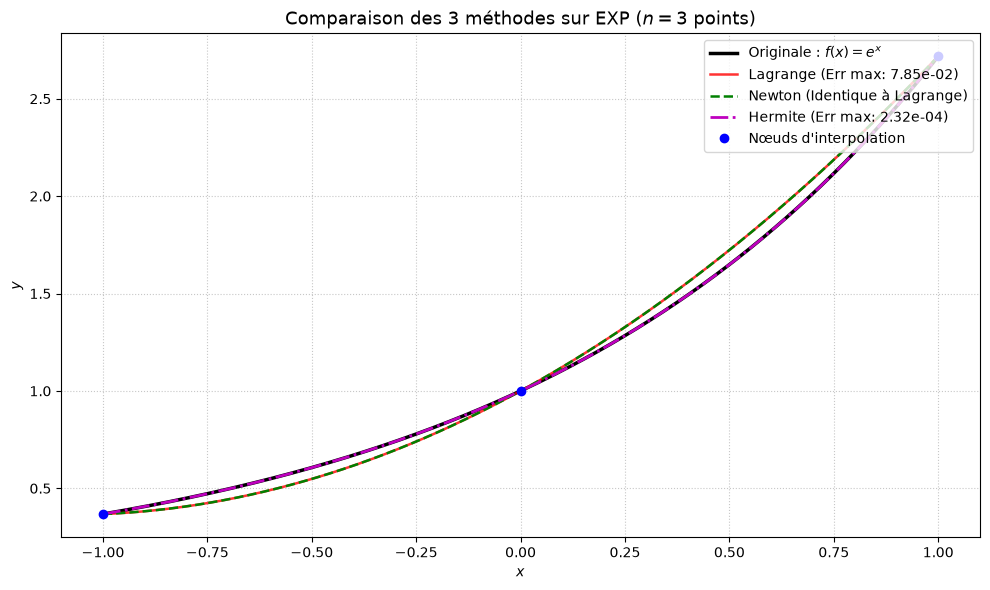

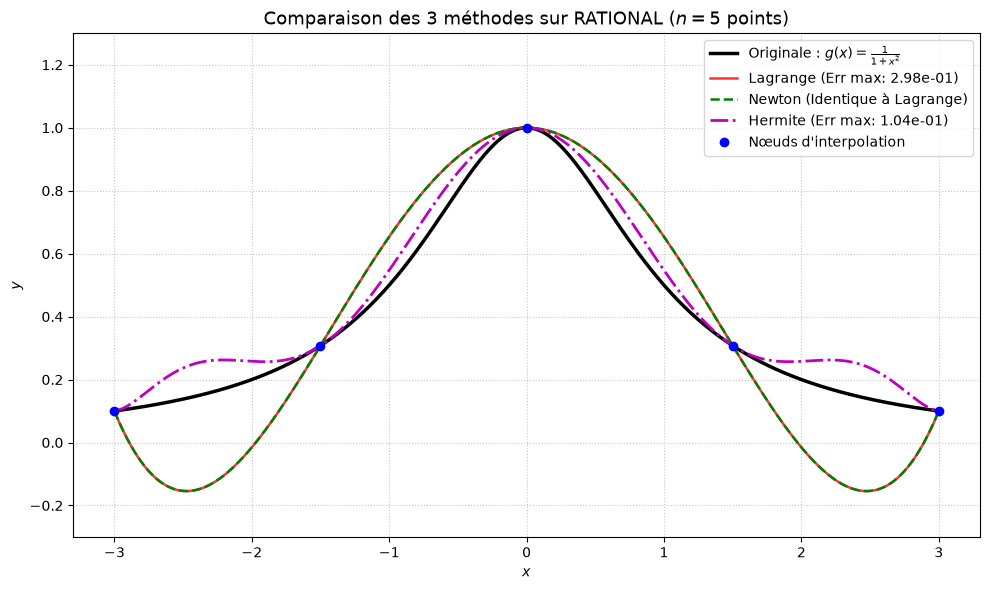

In [27]:
# Test 1 : Comparaison des 3 méthodes sur e^x avec 5 points
plot_interpolation(function_choice="exp", n=3)

# Test 2 : Comparaison sur g(x) = 1/(1+x^2) avec 5 points
# Hermite épouse très bien le sommet de la cloche grâce à la dérivée nulle en 0
plot_interpolation(function_choice="rational", n=5)
